# Singapore Parliamentary Debates — Family Norms Pilot
**Amaç:** 2025 verisinde marriage, singlehood, parenthood ve normative adulthood çerçevelerini keşfetmek. Bu notebook **otomatik bulguları kanıt olarak sunmaz**; bağlam incelemesi ve insan kodlaması için aday üretir. 2020–2025 verilerine genişletilebilir.

In [2]:
!pip install matplot

  Obtaining dependency information for matplot from https://files.pythonhosted.org/packages/89/0c/3bd66533148c8c642c56ed08e3a3847c48d2b4e4758ec73093eeb53b70d0/matplot-0.1.9-py2.py3-none-any.whl.metadata
  Obtaining dependency information for pyloco>=0.0.134 from https://files.pythonhosted.org/packages/f8/89/23c6628547cf88fb085182fe66f91c6b16b5706a05684f6589efcf064aee/pyloco-0.0.139-py2.py3-none-any.whl.metadata
  Obtaining dependency information for matplotlib>=3.1.1 from https://files.pythonhosted.org/packages/a6/c4/7f5f3601ee69baf072c0c7d3ce60c03e0618621c5a56c34a62a460e29d11/matplotlib-3.11.2-cp312-cp312-macosx_11_0_arm64.whl.metadata
  Using cached matplotlib-3.11.2-cp312-cp312-macosx_11_0_arm64.whl.metadata (80 kB)
  Obtaining dependency information for contourpy>=1.0.1 from https://files.pythonhosted.org/packages/dd/f5/c5bf67522d49a2222f3154fe46879451d26f0e35ece41770758a64ea78cb/contourpy-1.4.0-cp312-cp312-macosx_11_0_arm64.whl.metadata
  Using cached contourpy-1.4.0-cp312-cp312-m

In [3]:
# Gerekirse: %pip install pandas numpy matplotlib
from pathlib import Path
import pandas as pd, numpy as np, re, matplotlib.pyplot as plt
pd.set_option('display.max_colwidth', 180)
DATA_PATH = Path('speeches.csv')  # Dosya aynı klasörde olmalı; gerekirse tam yolu yazın
if not DATA_PATH.exists():
    DATA_PATH = Path('/Users/kemalgunay/PycharmProjects/sgparl/data/parliament_2025/speeches.csv')
df = pd.read_csv(DATA_PATH)
print('Rows, columns:', df.shape)
print(df.columns.tolist())
display(df.head(3))

Rows, columns: (9233, 16)
['date', 'speech_id', 'topic_id', 'speech_order', 'member_name_original', 'member_name', 'text', 'num_words', 'num_characters', 'num_sentences', 'num_syllables', 'party', 'gender', 'is_appointment', 'is_chairing', 'is_noise']


,date,speech_id,topic_id,speech_order,member_name_original,member_name,text,num_words,num_characters,num_sentences,num_syllables,party,gender,is_appointment,is_chairing,is_noise
0,2025-01-07,2025-01-07-T-002-S-00001,2025-01-07-T-002,1,NaN,NaN,[() Order for Second Reading read. ()],7,25,2,15,NaN,NaN,False,False,True
1,2025-01-07,2025-01-07-T-002-S-00002,2025-01-07-T-002,2,The Second Minister for Law (Mr Edwin Tong Chun Fai),Edwin Tong Chun Fai,"Mr Speaker, Sir, I move, ""That the Bill be now read a Second time."" Sir, as the House may recall, the current Simplified Insolvency Programme (SIP) was first introduced in 2021...",2476,12327,95,4426,PAP,M,True,False,False
2,2025-01-07,2025-01-07-T-002-S-00003,2025-01-07-T-002,3,Mr Speaker,Speaker,Mr Don Wee.,3,8,1,4,NaN,NaN,True,False,False


## 1. Veri kalitesi ve temizleme

In [4]:
df['date'] = pd.to_datetime(df['date'], errors='coerce')
for col in ['is_noise','is_chairing','is_appointment']:
    df[col] = df[col].astype('string').str.lower().eq('true')
df['text'] = df['text'].fillna('').astype(str)
df['num_words'] = pd.to_numeric(df['num_words'],errors='coerce')
print('Tarih:',df.date.min(),df.date.max())
print('Tekil topic:',df.topic_id.nunique(),'Konuşmacı:',df.member_name.nunique())
print('Eksik parti:',df.party.isna().mean().round(3),'Eksik gender:',df.gender.isna().mean().round(3))
print('Noise:',df.is_noise.sum(),'Chairing:',df.is_chairing.sum())
clean = df.loc[(~df.is_noise) & (~df.is_chairing) & (df.num_words >= 30)].copy()
print('Temizlenmiş konuşma:',len(clean))

Tarih: 2025-01-07 00:00:00 2025-11-06 00:00:00
Tekil topic: 2303 Konuşmacı: 141
Eksik parti: 0.22 Eksik gender: 0.221
Noise: 140 Chairing: 418
Temizlenmiş konuşma: 6850


## 2. Geniş aday taraması
Kelime eşleşmesi araştırma bulgusu değildir. Özellikle `single`, `family` gibi kelimeler bağlam dışında kullanılabilir. Birden çok temayı içeren konuşmalar ayrıca işaretlenir.

,matching_speeches
housing_costs,947
parenthood_fertility,560
gender_care,496
youth_transition,356
marriage_singlehood,135


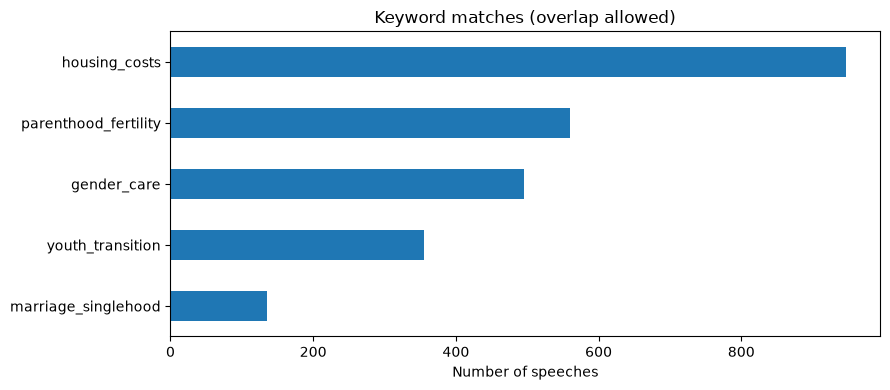

Aday konuşmalar: 352 Farklı gündem: 158


,date,member_name,party,topic_id,num_words,theme_hits
16,2025-01-07,Sun Xueling,PAP,2025-01-07-T-003,2698,2
91,2025-01-07,Tan See Leng,PAP,2025-01-07-T-007,4390,3
101,2025-01-07,Pritam Singh,WP,2025-01-07-T-009,3140,2
103,2025-01-07,Patrick Tay Teck Guan,PAP,2025-01-07-T-009,2581,2
116,2025-01-07,Denise Phua Lay Peng,PAP,2025-01-07-T-009,1778,3
118,2025-01-07,Chua Kheng Wee Louis,WP,2025-01-07-T-009,3088,2
271,2025-01-07,Desmond Choo,PAP,2025-01-07-T-023,127,2
272,2025-01-07,Sun Xueling,PAP,2025-01-07-T-023,263,2
319,2025-01-07,Gan Thiam Poh,PAP,2025-01-07-T-038,51,2
347,2025-01-07,Lim Wee Kiak,PAP,2025-01-07-T-052,80,2


In [5]:
PATTERNS = {
 'marriage_singlehood': r'\b(?:marriage|married|marry|marrying|singlehood|singles|unmarried|never.married|late marriage|delayed marriage)\b',
 'parenthood_fertility': r'\b(?:parenthood|parenting|parents?|motherhood|fatherhood|fertility|birth rates?|childbirth|having children|childcare)\b',
 'gender_care': r'\b(?:gender|women|woman|men|mothers?|fathers?|caregiving|caregivers?|maternity|paternity)\b',
 'youth_transition': r'\b(?:youth|young adults?|young couples?|young people|adulthood|life stages?|first.time buyers?)\b',
 'housing_costs': r'\b(?:housing|hdb|bto|affordab(?:le|ility)|cost of living|financial stability)\b'
}
for label,pattern in PATTERNS.items():
    clean[label] = clean.text.str.contains(pattern, flags=re.IGNORECASE, regex=True, na=False)
counts=clean[list(PATTERNS)].sum().sort_values(ascending=False)
display(counts.to_frame('matching_speeches'))
counts.sort_values().plot.barh(figsize=(9,4), title='Keyword matches (overlap allowed)')
plt.xlabel('Number of speeches');plt.tight_layout();plt.show()
clean['theme_hits'] = clean[list(PATTERNS)].sum(axis=1)
# Geniş havuz: evlilik/ebeveynlik teması ya da en az iki diğer tema
candidates = clean.loc[(clean.marriage_singlehood | clean.parenthood_fertility) & (clean.theme_hits >= 2)].copy()
print('Aday konuşmalar:',len(candidates),'Farklı gündem:',candidates.topic_id.nunique())
display(candidates[['date','member_name','party','topic_id','num_words','theme_hits']].head(15))

## 3. 5 Şubat 2025 aile tartışması: gündem ve konuşma sırası

In [10]:
day = clean.loc[clean.date.eq(pd.Timestamp('2025-02-05'))].copy()
summary = day.groupby('topic_id').agg(speeches=('speech_id','size'),matching=('marriage_singlehood','sum'),parenthood=('parenthood_fertility','sum')).sort_values(['matching','parenthood'],ascending=False)
display(summary.head(20))
# İlk gündemi elle seçebilir veya aşağıdaki otomatik ilk sıradakini kullanabilirsiniz.
if len(summary):
    selected_topic = summary.index[0]
    debate = day.loc[day.topic_id.eq(selected_topic)].sort_values('speech_order')
    print('Seçilen gündem:',selected_topic, '| Konuşmalar:',len(debate))
    display(debate[['speech_order','member_name','party','num_words','text']].head(20))

,speeches,matching,parenthood
topic_id,,,
2025-02-05-T-002,28,16,23
2025-02-05-T-005,27,9,13
2025-02-05-T-086,2,2,2
2025-02-05-T-058,2,2,0
2025-02-05-T-077,2,1,2
2025-02-05-T-012,11,0,7
2025-02-05-T-010,7,0,5
2025-02-05-T-014,7,0,4
2025-02-05-T-032,2,0,2


Seçilen gündem: 2025-02-05-T-002 | Konuşmalar: 28


,speech_order,member_name,party,num_words,text
1361,11,Hany Soh,PAP,3442,"Mr Speaker, I move*, ""That this House calls for the continued review and updating of policies to better support families, as well as the marriage and parenthood aspirations of ..."
1363,13,Zhulkarnain Abdul Rahim,PAP,2389,"Mr Speaker, Sir, I thank the hon Member Ms Hany Soh for moving this Motion. When Ms Hany Soh approached me to sponsor this Motion, I fully and readily supported it. I have four..."
1365,15,Chua Kheng Wee Louis,WP,2185,"Mr Speaker, it felt like it was not too long ago when I spoke on this topic of how we can better support Singaporeans in starting and raising families, even though this is a to..."
1367,17,Hany Soh,PAP,75,"Mr Speaker, I wish to raise a clarification to Mr Louis Chua. While I understand the context of his speech, but it is not clear from his speech whether he is in support of my M..."
1370,20,Leong Mun Wai,PSP,1900,"Mr Speaker, Sir, Singapore's TFR has been falling for many years. Last year, Elon Musk declared that Singapore is going extinct with our low birth rate. We do not need Elon Mus..."
1373,23,Speaker,NaN,51,"Hold on, Mr Leong. Let me just look through. Okay, the amendment submitted by Mr Leong Mun Wai is in order. Do you have copies available for Members? We will get these distribu..."
1374,24,Leong Mun Wai,PSP,94,"Sir, the PSP's amendment is, in the original Motion, ""in line 2, to delete 'continued review and updating', and insert 're-imagination'."" Sir, the Cambridge dictionary defines ..."
1375,25,Speaker,NaN,87,"There is one amendment proposed by Mr Leong Mun Wai to the Motion: ""In line 2, to delete the words 'continued review and updating' and insert 're-imagination'."". It may be conv..."
1376,26,Muhamad Faisal Bin Abdul Manap,WP,1125,"Sir, my speech would be in Malay. (In Malay): [Please refer to Vernacular Speech.] Sir, the phrase ""Family is the pillar of society"" aptly suits the Motion tabled before us. T..."
1378,28,Ng Ling Ling,PAP,2370,"Mr Speaker, I was born in the early 1970s, just seven years after our nation's Independence, to a typical Chinese family in Singapore then. I had the joy of growing up in a big..."


## 4. Bağlam içinde ifadeler (KWIC)
Kısa pasajları okuyarak yanlış pozitifleri ve olası normatif ifadeleri keşfedin.

In [13]:
def kwic(data, pattern, n=25, context=140):
    rows=[]
    for _,r in data.iterrows():
        m=re.search(pattern,r['text'],flags=re.I)
        if m:
            a=max(0,m.start()-context);z=min(len(r['text']),m.end()+context)
            rows.append({'date':r['date'],'speaker':r['member_name'],'topic_id':r['topic_id'],
                         'match':m.group(0),'context':r['text'][a:z].replace('\n',' ')})
        if len(rows)>=n:break
    return pd.DataFrame(rows)
display(kwic(candidates, r'\b(?:marriage|singlehood|parenthood|fertility|young couples?)\b', n=100))

,date,speaker,topic_id,match,context
0,2025-01-07,Tan See Leng,2025-01-07-T-007,marriage,"re Women's Development, these areas are important to ensure fair, merit-based treatment for men and women alike and to support our national marriage and parenthood objectives. ..."
1,2025-01-08,Sylvia Lim,2025-01-08-T-001,parenthood,"ny mental health condition. During hiring interviews, women especially are often asked about their caregiving responsibilities or potential parenthood plans. Regarding what sor..."
2,2025-02-04,Desmond Lee,2025-02-04-T-054,marriage,"If flat owners are unable to form an eligible family nucleus to retain flat ownership following the annulment of their marriage, the owners are required to surrender their flat..."
3,2025-02-04,Desmond Lee,2025-02-04-T-055,Parenthood,"ority through various schemes. For example, First-Timer (Parents and Married Couples), or FT(PMCs), get first priority under the Family and Parenthood Priority Scheme (FPPS), w..."
4,2025-02-04,Ong Ye Kung,2025-02-04-T-078,young couples,"eceive Government co-funding support and use MediSave for their treatments. From a population policy perspective, the Government encourages young couples to fulfil their marria..."
...,...,...,...,...,...
95,2025-09-25,Lee Hui Ying,2025-09-25-T-019,parenthood,"ng Singaporeans who are burdened with adulting responsibilities. They have just entered the workforce, just got married, just started their parenthood journey. They are finding..."
96,2025-09-25,Masagos Zulkifli B M M,2025-09-25-T-043,marriage,"pouses have remarried, and have three or more Singaporean children under their care and control, including those born within their previous marriage, are eligible for Large Fam..."
97,2025-09-26,Sun Xueling,2025-09-26-T-020,young couple,"rice levels to cater to buyers with different incomes and aspirations. Let me share two examples using the recent July BTO exercise. Take a young couple earning around $5,000 m..."
98,2025-09-26,Hany Soh,2025-09-26-T-020,parenthood,"to co-create a brighter future for Woodgrove, where ""G"" pertains to green living initiatives to sustain our environment; ""E"" for embracing parenthood to support our families; ..."


## 5. Ön kodlama için çerçeve sözlüğü
Bunlar **keşif amaçlı işaretleyicilerdir**; normatif çerçeve bulunduğunu ispatlamaz. Kodlama birimi tercihen paragraf olmalı, konuşma düzeyinde özetlenmelidir.

In [ ]:
FRAME_PATTERNS = {
 'economic_constraints':r'\b(?:affordab\w*|housing|financial burden|cost of living|career|work.life balance)\b',
 'demographic_sustainability':r'\b(?:birth rate|fertility|ageing population|population growth|demographic|total fertility rate)\b',
 'individual_autonomy':r'\b(?:personal choice|individual choice|freedom to choose|own decision|different paths|diverse aspirations)\b',
 'familial_responsibility':r'\b(?:family values|family as|strong families|family unit|family responsibilities|responsibility to family)\b',
 'gendered_expectations':r'\b(?:mothers? and fathers?|women and men|gender roles?|caregiving responsibilities|working mothers?)\b'
}
for name,pat in FRAME_PATTERNS.items():
    candidates[name+'_flag']=candidates.text.str.contains(pat,flags=re.I,regex=True,na=False)
display(candidates[[x+'_flag' for x in FRAME_PATTERNS]].sum().sort_values(ascending=False).to_frame('flagged'))
# Konuşma metnini okuyup otomatik etiketleri doğrulayın
cols=['date','speech_id','topic_id','member_name','party','gender','num_words','text']+[x+'_flag' for x in FRAME_PATTERNS]
display(candidates[cols].sample(min(10,len(candidates)),random_state=42))

## 6. İnsan kodlaması için 40 konuşmalık tabakalı örneklem
Gündemlerin tek bir oturumdan gelmesini engellemek için önce gündemler seçilir. `relevant` ve beş çerçeve elle doldurulur (0/1/uncertain). **Duruşu** ayrıca kaydedin: supports / contests / describes / unclear.

In [ ]:
rng=np.random.default_rng(42)
# Her gündemden en fazla 2 konuşma, tarih/gündem çeşitliliği
pool=candidates.sort_values(['date','topic_id','speech_order']).groupby('topic_id',group_keys=False).head(2)
sample=pool.sample(n=min(40,len(pool)),random_state=42).copy()
for col in ['relevant','economic_constraints','demographic_sustainability','individual_autonomy','familial_responsibility','gendered_expectations','stance','coder_notes']:
    sample['manual_'+col]=''
out=Path('pilot_manual_coding_2025.csv')
sample.to_csv(out,index=False,encoding='utf-8-sig')
print('Kaydedildi:',out.resolve())
display(sample[['date','member_name','topic_id','text','manual_relevant','manual_stance']].head(5))

## 7. Yıllara genişletme (2020–2025)
Önce her yılın aynı sütunlara sahip olduğunu doğrulayın. Dosyalar örneğin `speeches_2020.csv` biçimindeyse aşağıdaki kodu çalıştırın. Sadece 2025 dosyası mevcutsa analiz 2025 ile sınırlı kalır.

In [ ]:
paths=sorted(Path('.').glob('speeches_20*.csv'))
print('Bulunan yıllık dosyalar:',[p.name for p in paths])
if paths:
    all_years=pd.concat([pd.read_csv(p) for p in paths],ignore_index=True)
    all_years['year']=pd.to_datetime(all_years['date'],errors='coerce').dt.year
    display(all_years.groupby('year').agg(speeches=('speech_id','size'),topics=('topic_id','nunique')))
else:
    print('2020–2025 karşılaştırması için yıllık CSV dosyalarını notebook klasörüne ekleyin.')

### Yorumlama notları
- Ham konuşma sayıları milletvekili başına konuşma eğilimi değildir; parti, konuşmacı, gündem ve konuşma uzunluğu farklılıklarını hesaba katın.
- 5 Şubat 2025 yoğunluğu, yıl geneline yayılan söylem olarak genellenmemeli.
- Otomatik çerçeve işaretleri **destekleme/eleştirme** ayrımını yapmaz.
- Workshop özeti için yalnızca manuel doğrulanmış gözlemleri bulgu olarak yazın.